# Main experiment: adaptive vs fixed-time control

This notebook analyses the main experiment, the full factorial sweep in
`data/sweep_results.csv`, made with `python -m utils.experiments`. It is
separate from the one-factor experiments in `Analysis.ipynb`.

Every combination of these settings was run with 10 seeds (3,240 runs):

| Setting | Values |
|---|---|
| controller | untuned fixed-time (20 steps per phase), Webster fixed-time, adaptive |
| arrival rate (cars per approach per step, on average) | 0.05, 0.1, 0.15, 0.2 |
| north–south share of arrivals | 0.5 (balanced), 0.7, 0.9 |
| right-turn share (left turns fixed at 0.2) | 0.1, 0.3, 0.5 |
| reaction delay (chance a stopped car stalls) | 0, 0.1, 0.2 |

All three controllers see exactly the same arriving cars for a given seed, so
runs can be compared in pairs. Waits are in steps (about 1 s each) and are the
average over cars that arrived in the 2,000 measured steps and reached the
junction. Cars that arrive when the entry cell is occupied are turned away;
the share turned away is shown next to the waits, because a controller could
otherwise look good by letting fewer cars in.

Figures are saved to `figures/` for the report.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("../..")                     # project folder (this notebook is in notebooks/Results)
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

CONTROLLERS = ["fixed", "webster", "adaptive"]
LABELS = {"fixed": "Fixed-time (untuned)", "webster": "Fixed-time (Webster)", "adaptive": "Adaptive"}
COLOURS = {"fixed": "C0", "webster": "C2", "adaptive": "C1"}   # fixed and adaptive as in Analysis.ipynb
FACTORS = ["arrival_rate", "north_south_share", "right_turn_share", "reaction_delay"]
FACTOR_LABELS = {"arrival_rate": "Arrival rate (cars per approach per step)",
                 "north_south_share": "North–south share of arrivals",
                 "right_turn_share": "Right-turn share",
                 "reaction_delay": "Reaction delay (stall probability)"}


def load(name):
    # One row per run, plus the share of arriving cars that were turned away
    # (4 approaches x arrival_rate cars arrive per step, 400 x arrival_rate per 100 steps).
    df = pd.read_csv(ROOT / "data" / name)
    df["turned_away"] = df["blocked_arrivals"] / (400 * df["arrival_rate"])
    return df


def paired(df, factors=FACTORS):
    # One row per situation (settings + seed) with a column per controller's
    # mean wait, and adaptive's percentage reduction in wait against each fixed-time plan.
    wide = df.pivot_table(index=factors + ["seed"], columns="controller", values="mean_wait").reset_index()
    wide["vs_webster"] = 100 * (wide["webster"] - wide["adaptive"]) / wide["webster"]
    wide["vs_fixed"] = 100 * (wide["fixed"] - wide["adaptive"]) / wide["fixed"]
    return wide


def mean_and_ci(df, by, value):
    # Mean of `value` for each level of `by`, with a 95% interval over the 10 seeds
    # (each seed's runs are first averaged over the other settings).
    per_seed = df.groupby([by, "seed"])[value].mean().groupby(by)
    return per_seed.mean(), 1.96 * per_seed.std() / np.sqrt(per_seed.count())


main = load("sweep_results.csv")
pairs = paired(main)
print(len(main), "runs,", len(pairs), "paired situations")

3240 runs, 1080 paired situations


## 1. Waiting time and cars turned away

Each point averages 90 runs (3 right-turn shares × 3 reaction delays × 10
seeds); bars are 95% intervals over the seeds. The untuned plan gives every
phase 20 steps whatever the traffic, so it fails first, especially when most
traffic comes from one direction. Webster's plan and adaptive control both
cope, and adaptive waits are lower except at the highest arrival rate with
balanced traffic.

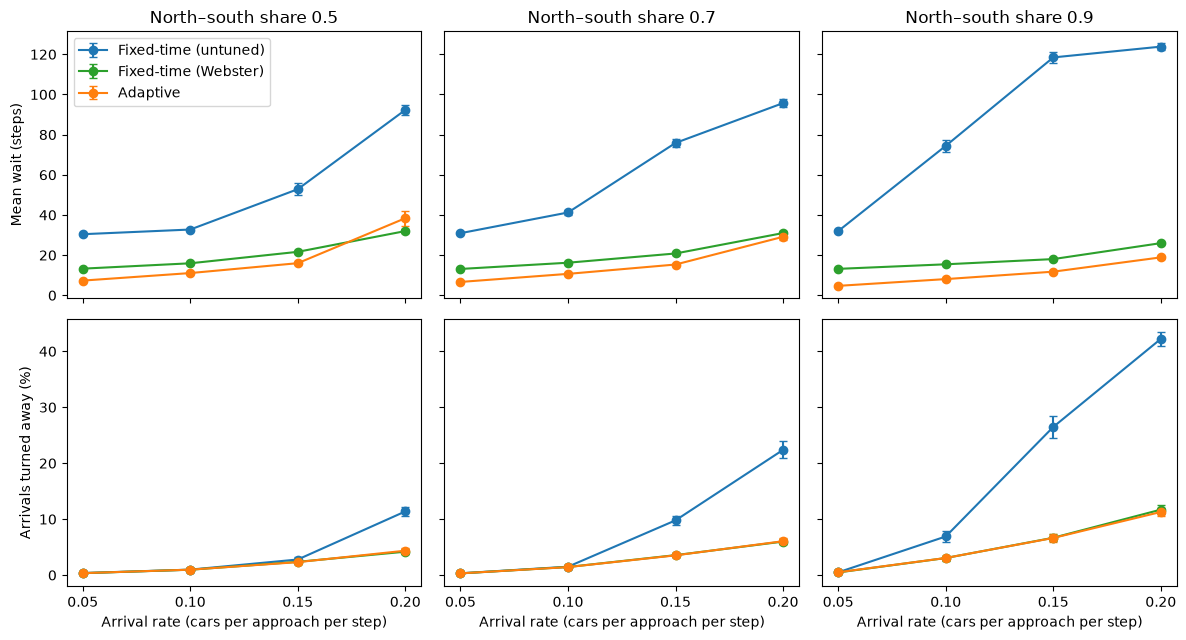

In [2]:
shares = sorted(main["north_south_share"].unique())
fig, axes = plt.subplots(2, len(shares), figsize=(12, 6.5), sharex=True, sharey="row")
for col, share in enumerate(shares):
    subset = main[main["north_south_share"] == share]
    for controller in CONTROLLERS:
        runs = subset[subset["controller"] == controller]
        for row, value in enumerate(["mean_wait", "turned_away"]):
            mean, ci = mean_and_ci(runs, "arrival_rate", value)
            scale = 100 if value == "turned_away" else 1
            axes[row, col].errorbar(mean.index, scale * mean, yerr=scale * ci, marker="o", capsize=3,
                                    color=COLOURS[controller], label=LABELS[controller])
    axes[0, col].set_title(f"North–south share {share}")
    axes[1, col].set_xticks(sorted(main["arrival_rate"].unique()))
    axes[1, col].set_xlabel("Arrival rate (cars per approach per step)")
axes[0, 0].set_ylabel("Mean wait (steps)")
axes[1, 0].set_ylabel("Arrivals turned away (%)")
axes[0, 0].legend()
fig.tight_layout()
fig.savefig(FIGURES / "wait_vs_arrival_rate.png", dpi=200)
plt.show()

## 2. Where adaptive control beats Webster's plan

Adaptive control's percentage reduction in mean wait compared with Webster's
plan, paired run by run and averaged over right-turn shares and seeds
(positive = adaptive waits less). Webster's plan is the fair baseline: it is
designed from the true average demand, which a real engineer would have to
estimate.

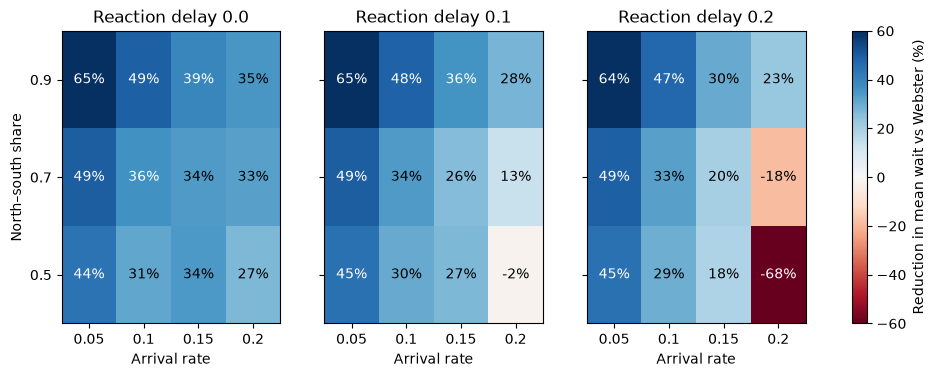

In [3]:
delays = sorted(pairs["reaction_delay"].unique())
fig, axes = plt.subplots(1, len(delays), figsize=(12, 3.8), sharey=True)
for ax, delay in zip(axes, delays):
    table = (pairs[pairs["reaction_delay"] == delay]
             .pivot_table(index="north_south_share", columns="arrival_rate", values="vs_webster"))
    image = ax.imshow(table.values, cmap="RdBu", vmin=-60, vmax=60, origin="lower", aspect="auto")
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            value = table.values[i, j]
            ax.text(j, i, f"{value:.0f}%", ha="center", va="center",
                    color="white" if abs(value) > 35 else "black")
    ax.set_xticks(range(table.shape[1]), table.columns)
    ax.set_yticks(range(table.shape[0]), table.index)
    ax.set_xlabel("Arrival rate")
    ax.set_title(f"Reaction delay {delay}")
axes[0].set_ylabel("North–south share")
fig.colorbar(image, ax=axes, label="Reduction in mean wait vs Webster (%)")
fig.savefig(FIGURES / "advantage_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Effect of each setting on the adaptive advantage

The same paired reduction, averaged over everything except one setting at a
time. The dashed line repeats the analysis for the robustness run in
`data/sweep_results_queued.csv`, where blocked arrivals wait off the map
(and their wait counts) instead of being turned away.

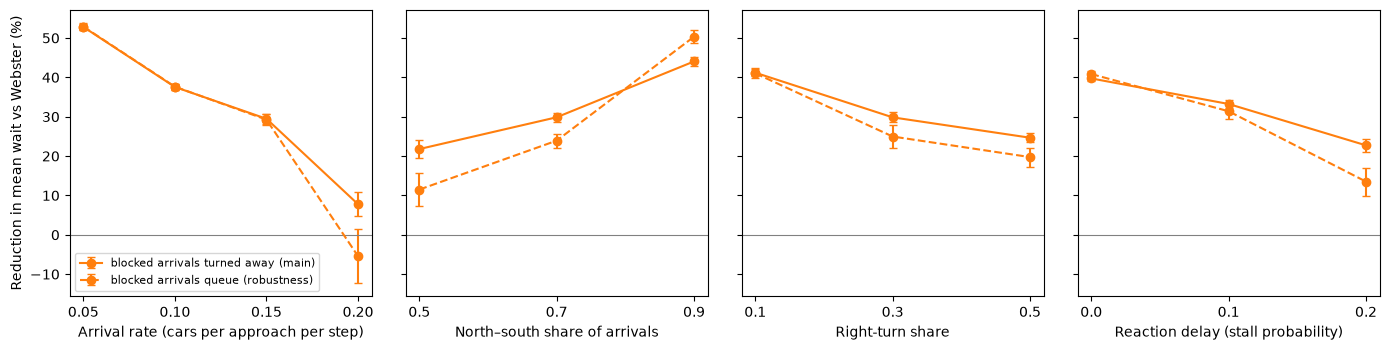

Adaptive's reduction in mean wait vs Webster (%), by setting
                        turned away  queued
arrival_rate      0.05         52.8    52.9
                  0.10         37.5    37.6
                  0.15         29.5    29.2
                  0.20          7.8    -5.4
north_south_share 0.50         21.8    11.5
                  0.70         29.9    23.9
                  0.90         44.0    50.3
right_turn_share  0.10         41.2    41.0
                  0.30         29.8    25.0
                  0.50         24.7    19.7
reaction_delay    0.00         39.7    40.8
                  0.10         33.2    31.4
                  0.20         22.7    13.5

Adaptive waits less than Webster in 93.1% of paired situations (90.6% with queuing), and less than untuned fixed-time in 98.9%.


In [4]:
queued = load("sweep_results_queued.csv")
queued_pairs = paired(queued)

fig, axes = plt.subplots(1, len(FACTORS), figsize=(14, 3.6), sharey=True)
for ax, factor in zip(axes, FACTORS):
    for data, style, label in [(pairs, "-", "blocked arrivals turned away (main)"),
                               (queued_pairs, "--", "blocked arrivals queue (robustness)")]:
        mean, ci = mean_and_ci(data, factor, "vs_webster")
        ax.errorbar(mean.index, mean, yerr=ci, marker="o", capsize=3, linestyle=style,
                    color=COLOURS["adaptive"], label=label)
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_xticks(sorted(pairs[factor].unique()))
    ax.set_xlabel(FACTOR_LABELS[factor])
axes[0].set_ylabel("Reduction in mean wait vs Webster (%)")
axes[0].legend(fontsize=8, loc="lower left")
fig.tight_layout()
fig.savefig(FIGURES / "advantage_by_setting.png", dpi=200)
plt.show()

summary = pd.concat({factor: pd.DataFrame({
    "turned away": pairs.groupby(factor)["vs_webster"].mean(),
    "queued": queued_pairs.groupby(factor)["vs_webster"].mean()}) for factor in FACTORS})
print("Adaptive's reduction in mean wait vs Webster (%), by setting")
print(summary.round(1))
print(f"\nAdaptive waits less than Webster in {100 * (pairs['vs_webster'] > 0).mean():.1f}% of paired situations "
      f"({100 * (queued_pairs['vs_webster'] > 0).mean():.1f}% with queuing), "
      f"and less than untuned fixed-time in {100 * (pairs['vs_fixed'] > 0).mean():.1f}%.")

## 4. Fairness between directions

Mean wait of cars from the north–south and east–west approaches. When most
traffic comes from north and south, the untuned plan gives each direction the
same green, so the busy direction waits much longer. Webster splits the green
in proportion to demand; adaptive control gives the busy direction more green
without leaving the quiet direction waiting much longer.

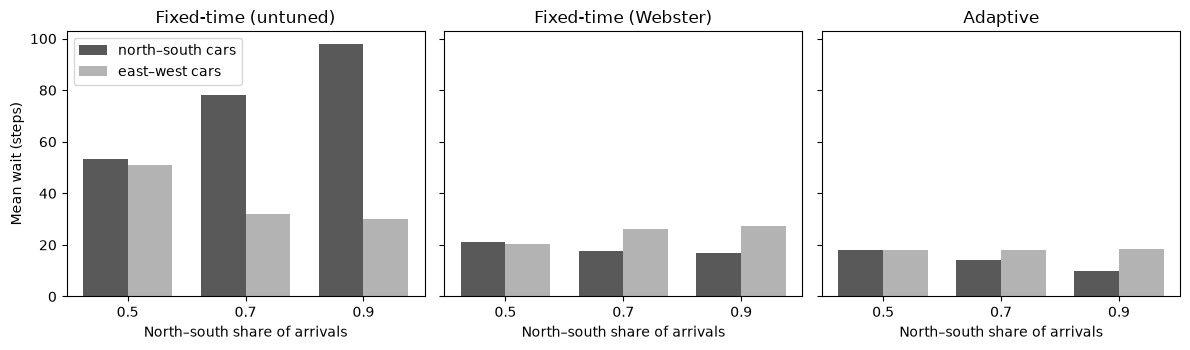

In [5]:
fig, axes = plt.subplots(1, len(CONTROLLERS), figsize=(12, 3.6), sharey=True)
width = 0.38
for ax, controller in zip(axes, CONTROLLERS):
    runs = main[main["controller"] == controller].groupby("north_south_share")[["wait_ns", "wait_ew"]].mean()
    x = np.arange(len(runs))
    ax.bar(x - width / 2, runs["wait_ns"], width, label="north–south cars", color="0.35")
    ax.bar(x + width / 2, runs["wait_ew"], width, label="east–west cars", color="0.7")
    ax.set_xticks(x, runs.index)
    ax.set_xlabel("North–south share of arrivals")
    ax.set_title(LABELS[controller])
axes[0].set_ylabel("Mean wait (steps)")
axes[0].legend()
fig.tight_layout()
fig.savefig(FIGURES / "fairness.png", dpi=200)
plt.show()

## 5. What the controllers do over time

Cars waiting in the north–south and east–west pockets during the first 300
measured steps of one example run (arrival rate 0.15, 90% of traffic from
north and south, seed 0), from `data/example_runs.npz`. Shading shows which
direction has a green light (white = all-red). The fixed plans cycle at the
same pace whatever the queues; adaptive control switches as soon as another
phase's cars have waited longer, so its queues stay short.

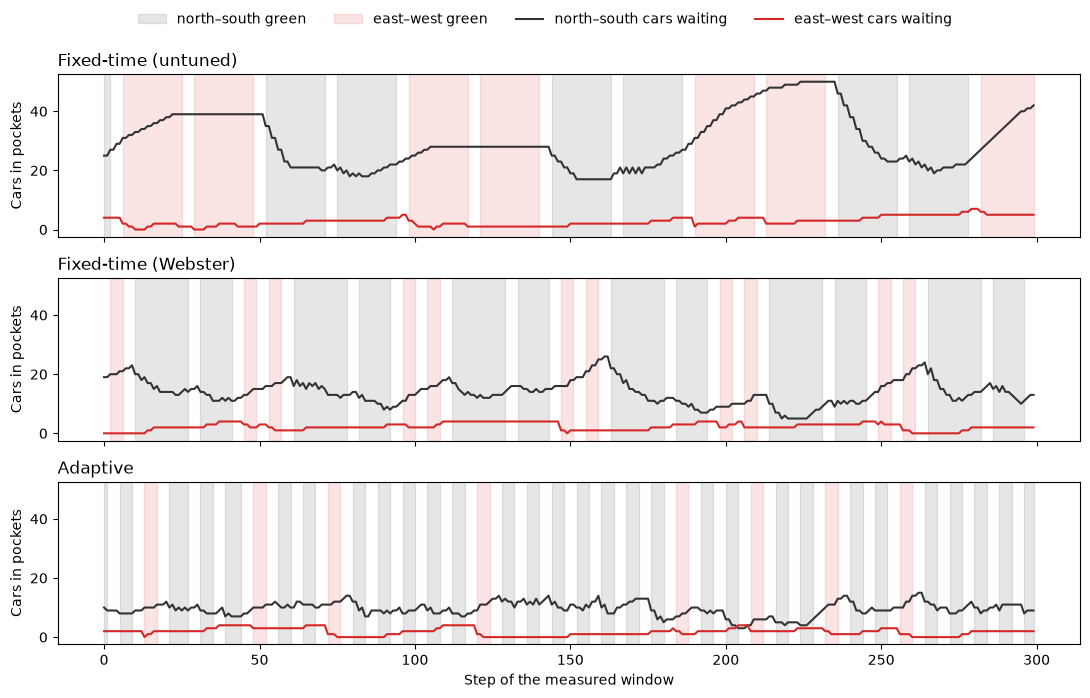

In [6]:
examples = np.load(ROOT / "data" / "example_runs.npz")
labels = list(examples["labels"])
steps = 300
fig, axes = plt.subplots(len(CONTROLLERS), 1, figsize=(11, 7), sharex=True, sharey=True)
for ax, controller in zip(axes, CONTROLLERS):
    i = labels.index(f"controller={controller}, arrival_rate=0.15, north_south_share=0.9, "
                     "right_turn_share=0.3, reaction_delay=0.0, seed=0")
    queues = examples[f"queues_{i}"][:steps]           # steps x approaches (N, E, S, W) x moves
    phases = examples[f"phases_{i}"][:steps]           # 0, 1 = north-south green; 2, 3 = east-west
    t = np.arange(steps)
    ax.fill_between(t, 0, 1, where=np.isin(phases, [0, 1]), color="0.35", alpha=0.15,
                    transform=ax.get_xaxis_transform(), step="mid", label="north–south green")
    ax.fill_between(t, 0, 1, where=np.isin(phases, [2, 3]), color="C3", alpha=0.12,
                    transform=ax.get_xaxis_transform(), step="mid", label="east–west green")
    ax.plot(t, queues[:, [0, 2]].sum(axis=(1, 2)), color="0.2", label="north–south cars waiting")
    ax.plot(t, queues[:, [1, 3]].sum(axis=(1, 2)), color="C3", label="east–west cars waiting")
    ax.set_title(LABELS[controller], loc="left")
    ax.set_ylabel("Cars in pockets")
axes[-1].set_xlabel("Step of the measured window")
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.legend(*axes[0].get_legend_handles_labels(), ncol=4, loc="upper center", frameon=False)
fig.savefig(FIGURES / "example_time_series.png", dpi=200)
plt.show()

## 6. Sensitivity tests

**Left-turn share** (`data/sensitivity_left.csv`, `python -m utils.experiments --left`).
The main experiment keeps 20% of cars turning left. Left turns go on the
same green as straight-on cars, in their own pocket, so changing the left
share mainly moves load between the left and straight pockets of the same
phase. Balanced traffic, 30% right turns, no reaction delay, 10 seeds.

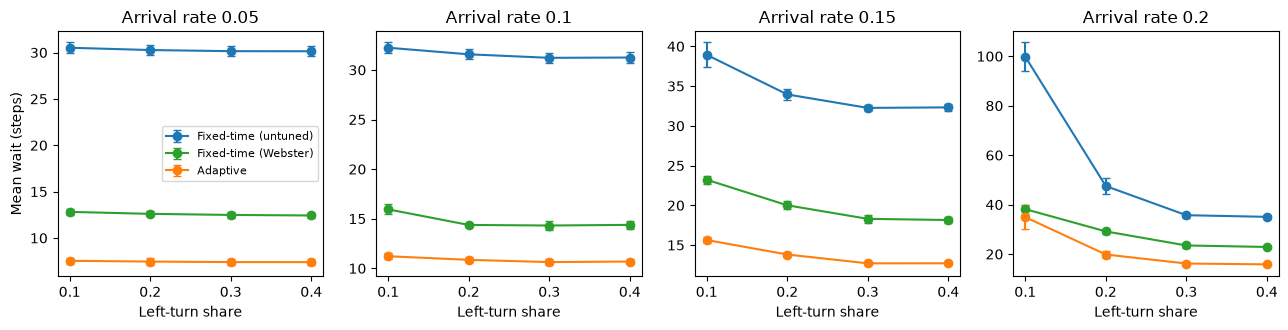

In [7]:
left = load("sensitivity_left.csv")
rates = sorted(left["arrival_rate"].unique())
fig, axes = plt.subplots(1, len(rates), figsize=(13, 3.4))
for ax, rate in zip(axes, rates):
    for controller in CONTROLLERS:
        runs = left[(left["arrival_rate"] == rate) & (left["controller"] == controller)]
        mean, ci = mean_and_ci(runs, "left_turn_share", "mean_wait")
        ax.errorbar(mean.index, mean, yerr=ci, marker="o", capsize=3,
                    color=COLOURS[controller], label=LABELS[controller])
    ax.set_title(f"Arrival rate {rate}")
    ax.set_xlabel("Left-turn share")
axes[0].set_ylabel("Mean wait (steps)")
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "left_turn_sensitivity.png", dpi=200)
plt.show()

**Pocket lengths** (`data/sensitivity_pockets.csv`, `python -m utils.experiments --pockets`).
The main experiment uses 10-cell pockets. Spillback is measured per 100 steps as
`full_pocket_blocks`, the times a car at the split cannot enter its pocket
because it is full, and `other_movement_blocks`, the times that car also
holds up the car behind it, which is heading for a different pocket.

In [8]:
pockets = pd.read_csv(ROOT / "data" / "sensitivity_pockets.csv")
table = pockets.pivot_table(index=["straight_pocket_length", "turn_pocket_length"], columns="controller",
                            values=["full_pocket_blocks", "other_movement_blocks", "mean_wait"])[["full_pocket_blocks", "other_movement_blocks", "mean_wait"]]
table.round(1)

full_pocket_blocks                \
controller                                          adaptive fixed webster   
straight_pocket_length turn_pocket_length                                    
10                     5                                 0.7  27.4     3.7   
                       10                                0.0   1.4     0.1   
                       20                                0.0   0.8     0.1   
20                     5                                 0.7  26.5     3.6   
                       10                                0.0   0.6     0.0   
                       20                                0.0   0.0     0.0   

                                          other_movement_blocks                \
controller                                             adaptive fixed webster   
straight_pocket_length turn_pocket_length                                       
10                     5                                    0.2  11.5     1.3   
                       10                                   0.0   0.5     0.0   
                       20                                   0.0   0.2     0.0   
20                     5                                    0.2  11.3     1.3   
                       10                                   0.0   0.4     0.0   
                       20                                   0.0   0.0     0.0   

                                          mean_wait                
controller                                 adaptive fixed webster  
straight_pocket_length turn_pocket_length                          
10                     5                       12.9  35.5    17.8  
                       10                      12.8  32.6    17.6  
                       20                      12.8  32.5    17.6  
20                     5                       12.9  35.1    17.7  
                       10                      12.8  32.5    17.6  
                       20                      12.8  32.5    17.6